In [4]:
%pip install numpy matplotlib scikit-learn pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\elsto\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier

# Make the random sequence repeatable
np.random.seed(42)

# Load the dataset included with scikit-learn
breast_cancer_data = load_breast_cancer()

X = breast_cancer_data.data
y = breast_cancer_data.target
feature_names = breast_cancer_data.feature_names

print("Number of records:", X.shape[0])
print("Number of features:", X.shape[1])

Number of records: 569
Number of features: 30


ENGE707 Week 5 Lab: Genetic Algorithms

Running Maximise Ones Demo...
Maximise Ones Problem
Best solution: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
Best fitness: 20


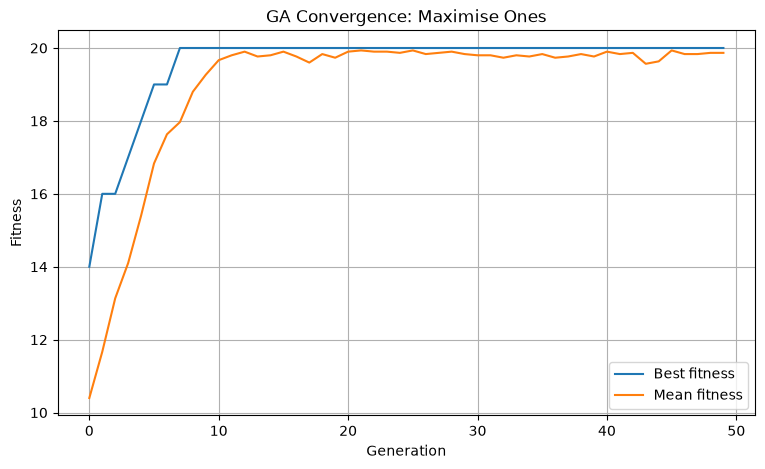


Running Parameter Experiments...
Parameter Experiment Results
Default settings Best fitness: 20 Best solution: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
Low mutation Best fitness: 20 Best solution: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
High mutation Best fitness: 16 Best solution: [1 1 1 0 0 1 1 1 1 1 1 1 1 0 1 1 1 1 1 0]
Small population Best fitness: 20 Best solution: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
Large population Best fitness: 20 Best solution: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
Low crossover Best fitness: 20 Best solution: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


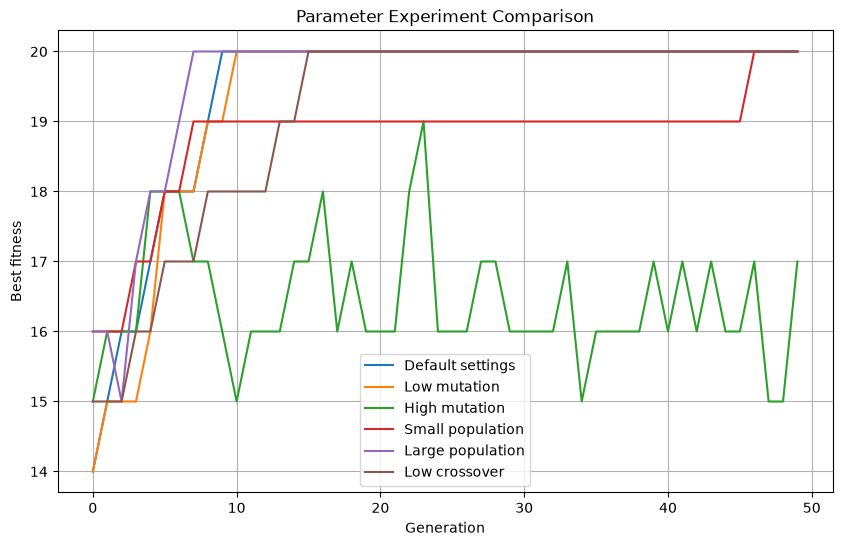


Running Feature Selection Demo...
Feature Selection Problem
Number of available features: 30
Best chromosome: [1 1 0 1 0 0 0 1 1 1 0 0 0 1 0 1 0 0 1 0 1 1 0 0 0 0 0 0 1 1]
Number of selected features: 13
Selected feature indices: [ 0  1  3  7  8  9 13 15 18 20 21 28 29]
Selected feature names:
mean radius
mean texture
mean area
mean concave points
mean symmetry
mean fractal dimension
area error
compactness error
symmetry error
worst radius
worst texture
worst symmetry
worst fractal dimension
Best GA fitness: 0.9552692128551467
Accuracy using selected features: 0.95960254618848
Accuracy using all features: 0.9173420276354604


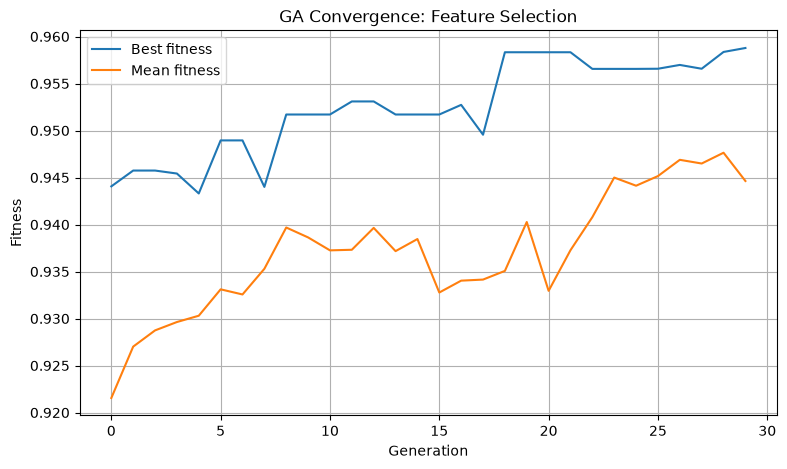


Lab complete


In [7]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier

np.random.seed(42)

# Load the feature-selection dataset
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names


########################################
# Fitness: maximise ones
########################################
def ones_fitness(chromosome):
    """Calculate fitness for the maximise-ones problem."""
    return np.sum(chromosome)


########################################
# Create a random binary population
########################################
def create_population(pop_size, chromosome_length):
    """Create a population of random binary chromosomes."""
    population = []

    for i in range(pop_size):
        chromosome = np.random.randint(0, 2, chromosome_length)
        population.append(chromosome)

    return np.array(population)


########################################
# Tournament selection
########################################
def tournament_selection(population, fitness_values, tournament_size):
    """Select one parent using tournament selection."""
    selected_indices = np.random.choice(
        len(population),
        tournament_size,
        replace=False
    )

    selected_fitness = fitness_values[selected_indices]
    best_position = np.argmax(selected_fitness)
    best_index = selected_indices[best_position]

    return population[best_index].copy()


########################################
# One-point crossover
########################################
def one_point_crossover(parent1, parent2, crossover_rate):
    """Create two children using one-point crossover."""
    random_value = np.random.rand()

    if random_value < crossover_rate:
        point = np.random.randint(1, len(parent1))

        child1 = np.concatenate((parent1[:point], parent2[point:]))
        child2 = np.concatenate((parent2[:point], parent1[point:]))

        return child1, child2

    return parent1.copy(), parent2.copy()


########################################
# Bit-flip mutation
########################################
def mutate(chromosome, mutation_rate):
    """Apply bit-flip mutation to a chromosome."""
    mutated_chromosome = chromosome.copy()

    for i in range(len(mutated_chromosome)):
        random_value = np.random.rand()

        if random_value < mutation_rate:
            mutated_chromosome[i] = 1 - mutated_chromosome[i]

    return mutated_chromosome


########################################
# Genetic Algorithm
########################################
def genetic_algorithm(
    fitness_function,
    chromosome_length,
    pop_size,
    generations,
    crossover_rate,
    mutation_rate,
    tournament_size
):
    """Run a binary Genetic Algorithm."""
    population = create_population(pop_size, chromosome_length)

    best_fitness_history = []
    mean_fitness_history = []

    for generation in range(generations):
        fitness_values = []

        for chromosome in population:
            score = fitness_function(chromosome)
            fitness_values.append(score)

        fitness_values = np.array(fitness_values)

        best_fitness = np.max(fitness_values)
        mean_fitness = np.mean(fitness_values)

        best_fitness_history.append(best_fitness)
        mean_fitness_history.append(mean_fitness)

        new_population = []

        while len(new_population) < pop_size:
            parent1 = tournament_selection(
                population, fitness_values, tournament_size
            )
            parent2 = tournament_selection(
                population, fitness_values, tournament_size
            )

            child1, child2 = one_point_crossover(
                parent1, parent2, crossover_rate
            )

            child1 = mutate(child1, mutation_rate)
            child2 = mutate(child2, mutation_rate)

            new_population.append(child1)

            if len(new_population) < pop_size:
                new_population.append(child2)

        population = np.array(new_population)

    # Evaluate the final population
    final_fitness_values = []

    for chromosome in population:
        score = fitness_function(chromosome)
        final_fitness_values.append(score)

    final_fitness_values = np.array(final_fitness_values)

    best_index = np.argmax(final_fitness_values)
    best_solution = population[best_index].copy()
    best_score = final_fitness_values[best_index]

    return (
        best_solution,
        best_score,
        best_fitness_history,
        mean_fitness_history
    )


########################################
# Plot convergence
########################################
def plot_convergence(best_history, mean_history, title):
    """Plot best and mean fitness across generations."""
    plt.figure(figsize=(9, 5))
    plt.plot(best_history, label="Best fitness")
    plt.plot(mean_history, label="Mean fitness")
    plt.xlabel("Generation")
    plt.ylabel("Fitness")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


########################################
# Task 1: Maximise Ones
########################################
def run_maximise_ones_demo():
    """Run the maximise-ones Genetic Algorithm example."""
    best_solution, best_score, best_history, mean_history = (
        genetic_algorithm(
            fitness_function=ones_fitness,
            chromosome_length=20,
            pop_size=30,
            generations=50,
            crossover_rate=0.8,
            mutation_rate=0.01,
            tournament_size=3
        )
    )

    print("Maximise Ones Problem")
    print("Best solution:", best_solution)
    print("Best fitness:", best_score)

    plot_convergence(
        best_history,
        mean_history,
        "GA Convergence: Maximise Ones"
    )


########################################
# Task 2: Parameter Experiments
########################################
def run_parameter_experiments():
    """Run experiments with different GA parameters."""
    experiments = [
        ["Default settings", 30, 50, 0.8, 0.01, 3],
        ["Low mutation", 30, 50, 0.8, 0.001, 3],
        ["High mutation", 30, 50, 0.8, 0.2, 3],
        ["Small population", 10, 50, 0.8, 0.01, 3],
        ["Large population", 100, 50, 0.8, 0.01, 3],
        ["Low crossover", 30, 50, 0.2, 0.01, 3]
    ]

    plt.figure(figsize=(10, 6))
    print("Parameter Experiment Results")

    for experiment in experiments:
        (
            name,
            pop_size,
            generations,
            crossover_rate,
            mutation_rate,
            tournament_size
        ) = experiment

        best_solution, best_score, best_history, mean_history = (
            genetic_algorithm(
                fitness_function=ones_fitness,
                chromosome_length=20,
                pop_size=pop_size,
                generations=generations,
                crossover_rate=crossover_rate,
                mutation_rate=mutation_rate,
                tournament_size=tournament_size
            )
        )

        print(
            name,
            "Best fitness:", best_score,
            "Best solution:", best_solution
        )

        plt.plot(best_history, label=name)

    plt.xlabel("Generation")
    plt.ylabel("Best fitness")
    plt.title("Parameter Experiment Comparison")
    plt.legend()
    plt.grid(True)
    plt.show()


########################################
# Fitness: feature selection
########################################
def feature_selection_fitness(chromosome):
    """Calculate cross-validation accuracy minus a feature penalty."""
    number_selected = np.sum(chromosome)

    if number_selected == 0:
        return 0

    selected_features = np.where(chromosome == 1)[0]
    X_selected = X[:, selected_features]

    model = DecisionTreeClassifier(random_state=42)

    scores = cross_val_score(
        model,
        X_selected,
        y,
        cv=5,
        scoring="accuracy"
    )

    accuracy = np.mean(scores)
    penalty = 0.01 * (number_selected / len(chromosome))

    return accuracy - penalty


########################################
# Task 3: Feature Selection
########################################
def run_feature_selection_demo():
    """Run the Genetic Algorithm for feature selection."""
    number_of_features = X.shape[1]

    best_solution, best_score, best_history, mean_history = (
        genetic_algorithm(
            fitness_function=feature_selection_fitness,
            chromosome_length=number_of_features,
            pop_size=30,
            generations=30,
            crossover_rate=0.8,
            mutation_rate=1 / number_of_features,
            tournament_size=3
        )
    )

    selected_indices = np.where(best_solution == 1)[0]
    selected_names = feature_names[selected_indices]

    print("Feature Selection Problem")
    print("Number of available features:", number_of_features)
    print("Best chromosome:", best_solution)
    print("Number of selected features:", len(selected_indices))
    print("Selected feature indices:", selected_indices)

    print("Selected feature names:")
    for name in selected_names:
        print(name)

    print("Best GA fitness:", best_score)

    # Recover accuracy before the feature penalty
    if len(selected_indices) > 0:
        selected_accuracy = (
            best_score + 0.01 * len(selected_indices) / number_of_features
        )
        print("Accuracy using selected features:", selected_accuracy)
    else:
        print("No features selected; selected-feature accuracy is undefined.")

    # Accuracy using all features
    model = DecisionTreeClassifier(random_state=42)

    all_feature_scores = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring="accuracy"
    )

    all_feature_accuracy = np.mean(all_feature_scores)
    print("Accuracy using all features:", all_feature_accuracy)

    plot_convergence(
        best_history,
        mean_history,
        "GA Convergence: Feature Selection"
    )


########################################
# Run all demonstrations
########################################
def lab_05():
    """Run all lab demonstrations."""
    print("ENGE707 Week 5 Lab: Genetic Algorithms")

    print("\nRunning Maximise Ones Demo...")
    run_maximise_ones_demo()

    print("\nRunning Parameter Experiments...")
    run_parameter_experiments()

    print("\nRunning Feature Selection Demo...")
    run_feature_selection_demo()

    print("\nLab complete")


if __name__ == "__main__":
    lab_05()